# Data Preparation III - Feature Selection: **Filter Method**

In [1]:
# Read the cleaned dataset (clean_df.csv) into a DataFrame and display the first few rows
import pandas as pd

df_clean = pd.read_csv('clean_df.csv')
display(df_clean.head())


,Unnamed: 0,symboling,normalized-losses,wheel-base,length,width,height,curb-weight,engine-size,bore,...,num-of-cylinders_twelve,num-of-cylinders_two,fuel-system_1bbl,fuel-system_2bbl,fuel-system_4bbl,fuel-system_idi,fuel-system_mfi,fuel-system_mpfi,fuel-system_spdi,fuel-system_spfi
0,0,3,122.0,88.6,168.8,64.1,48.8,2548,130,3.47,...,0,0,0,0,0,0,0,1,0,0
1,1,3,122.0,88.6,168.8,64.1,48.8,2548,130,3.47,...,0,0,0,0,0,0,0,1,0,0
2,2,1,122.0,94.5,171.2,65.5,52.4,2823,152,2.68,...,0,0,0,0,0,0,0,1,0,0
3,3,2,164.0,99.8,176.6,66.2,54.3,2337,109,3.19,...,0,0,0,0,0,0,0,1,0,0
4,4,2,164.0,99.4,176.6,66.4,54.3,2824,136,3.19,...,0,0,0,0,0,0,0,1,0,0


#### Convert horsepower-binned from categorical to numeric using Ordinal Encoding


In [2]:
from sklearn.preprocessing import OrdinalEncoder

encoder = OrdinalEncoder(categories=[['Low', 'Medium', 'High']])
encoded_horse = encoder.fit_transform(df_clean[["horsepower-binned"]])

print(f"Encoded horsepower-binned: {encoded_horse}")

Encoded horsepower-binned: [[0.]
 [0.]
 [1.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [1.]
 [0.]
 [0.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [1.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [1.]
 [1.]
 [2.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [1.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [1.]
 [0.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [1.]
 [1.]
 [1.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [1.]
 [1.]
 [1.]
 [1.]
 [2.]
 [1.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [1.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [1.]
 [1.]
 [2.]
 [2.]
 [2.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [1.]
 [1.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 

In [3]:
# merge the new dataframe to the original datafram
encoded_horse_df = pd.DataFrame(encoded_horse, columns=['horsepower-binned_encoded'])
df_clean = pd.concat([df_clean, encoded_horse_df], axis=1)

# drop original column "horsepower-binned" from "df"
df_clean = df_clean.drop('horsepower-binned', axis = 1)

In [4]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 77 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Unnamed: 0                 201 non-null    int64  
 1   symboling                  201 non-null    int64  
 2   normalized-losses          201 non-null    float64
 3   wheel-base                 201 non-null    float64
 4   length                     201 non-null    float64
 5   width                      201 non-null    float64
 6   height                     201 non-null    float64
 7   curb-weight                201 non-null    int64  
 8   engine-size                201 non-null    int64  
 9   bore                       201 non-null    float64
 10  stroke                     201 non-null    float64
 11  compression-ratio          201 non-null    float64
 12  horsepower                 201 non-null    float64
 13  peak-rpm                   201 non-null    float64

In [5]:
# drop the first column "unnamed" since it is just an ID (not used)
df_clean = df_clean.drop('Unnamed: 0', axis = 1)

In [6]:
# Move the target variable "price" to the last column
# Get a list of all columns
cols = df_clean.columns.tolist()

# Remove 'price' from the list
cols.remove('price')

# Append 'price' to the end of the list
cols.append('price')

# Reindex the DataFrame with the new column order
df_clean = df_clean[cols]

# Display the columns to confirm the change
print(df_clean.columns)

Index(['symboling', 'normalized-losses', 'wheel-base', 'length', 'width',
       'height', 'curb-weight', 'engine-size', 'bore', 'stroke',
       'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg',
       'highway-mpg', 'make_alfa-romero', 'make_audi', 'make_bmw',
       'make_chevrolet', 'make_dodge', 'make_honda', 'make_isuzu',
       'make_jaguar', 'make_mazda', 'make_mercedes-benz', 'make_mercury',
       'make_mitsubishi', 'make_nissan', 'make_peugot', 'make_plymouth',
       'make_porsche', 'make_renault', 'make_saab', 'make_subaru',
       'make_toyota', 'make_volkswagen', 'make_volvo', 'fuel-type_diesel',
       'fuel-type_gas', 'aspiration_std', 'aspiration_turbo',
       'num-of-doors_four', 'num-of-doors_two', 'body-style_convertible',
       'body-style_hardtop', 'body-style_hatchback', 'body-style_sedan',
       'body-style_wagon', 'drive-wheels_4wd', 'drive-wheels_fwd',
       'drive-wheels_rwd', 'engine-location_front', 'engine-location_rear',
       'engine-type_

# Feature Selection Methods
The following are methods for feature selection:

1. Filter: filters features based on the statistical indicators for the feature vectors and those common to the feature vectors and the target variables.
2. Wrapper: attempts to use different feature subsets for modeling and use the model precision as an evaluation indicator for the feature subsets.
3. Embedded: evaluates feature weights during model training and scores the importance of the features.


##1. Filter Method

##Test the continuous variable correlation.
If two continuous independent variables are highly correlated, delete one of the two independent
variables or extract common information from the two independent variables.

The method parameter indicates the method for calculating the correlation coefficient. The options
are as follows:
* pearson: Pearson correlation coefficient.
* kendall: correlation coefficient for unordered categorical variables.
* spearman: Spearman correlation coefficient, which is mainly used for correlation analysis of
non-linearly and non-normally distributed data.

<Axes: >

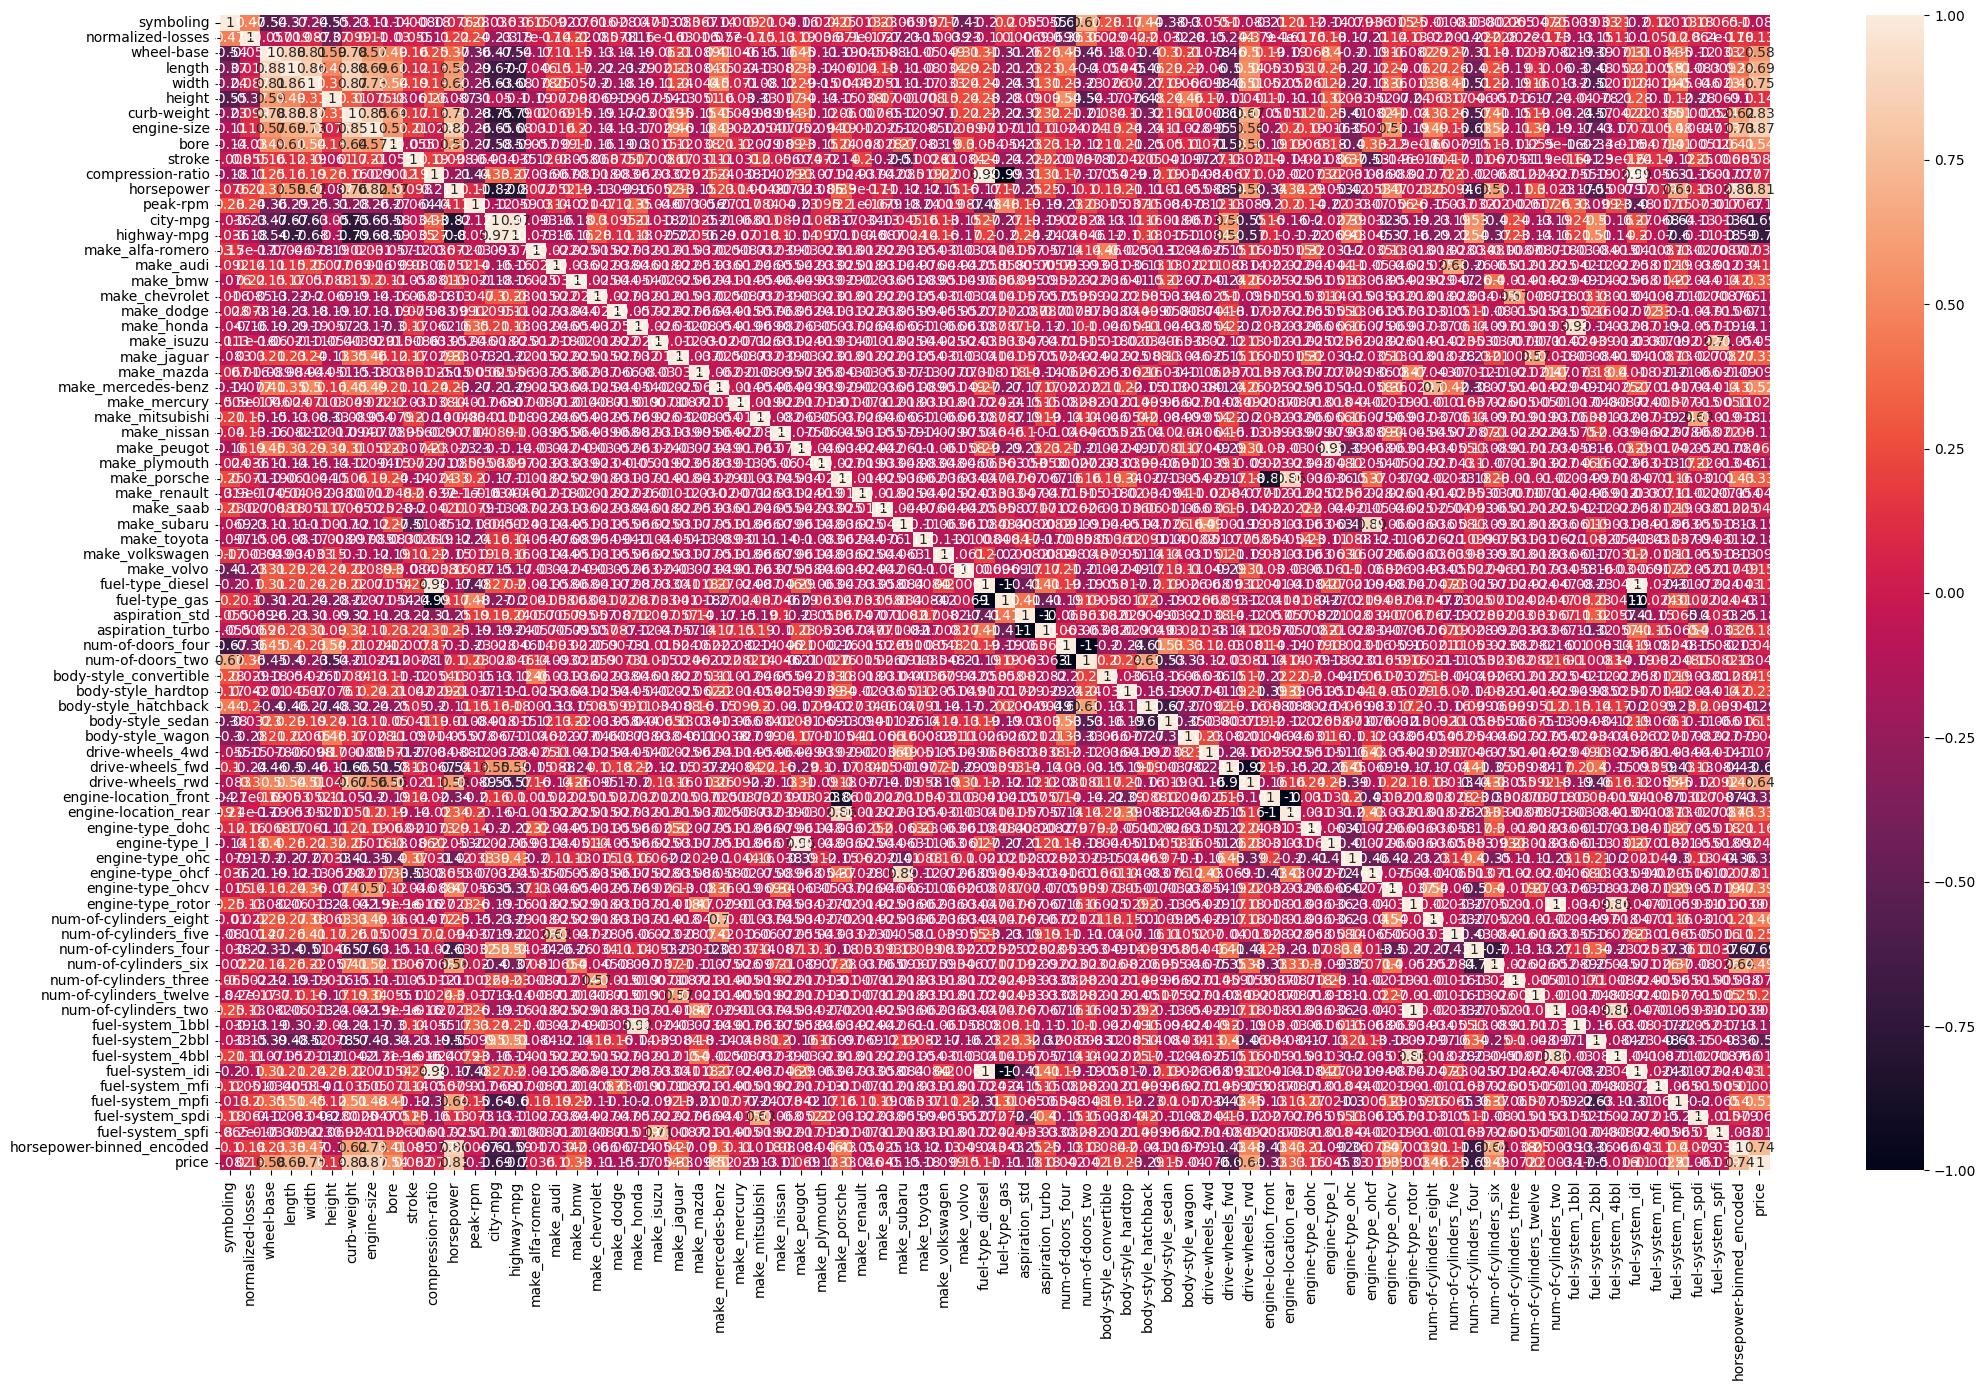

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
corr_matrix = df_clean.corr(method='pearson')
plt.figure(figsize=(25, 15))
sns.heatmap(corr_matrix, annot= True) # Display the correlation between the heatmap and variables in a visualize manner.



Calculate the correlation coefficient between independent variables and target, select the independent variables whose correlation coefficient is greater than 0.1.



In [8]:
high_corr = []
for column in corr_matrix.columns:
  if abs(corr_matrix.loc[column, 'price']) >= 0.1 and column != 'price':
    high_corr.append(column)

print("Variables with absolute correlation >= 0.1 with price:")
print(high_corr)

Variables with absolute correlation >= 0.1 with price:
['normalized-losses', 'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-size', 'bore', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'make_audi', 'make_bmw', 'make_chevrolet', 'make_dodge', 'make_honda', 'make_jaguar', 'make_mercedes-benz', 'make_mitsubishi', 'make_nissan', 'make_plymouth', 'make_porsche', 'make_subaru', 'make_toyota', 'make_volvo', 'fuel-type_diesel', 'fuel-type_gas', 'aspiration_std', 'aspiration_turbo', 'body-style_convertible', 'body-style_hardtop', 'body-style_hatchback', 'body-style_sedan', 'drive-wheels_fwd', 'drive-wheels_rwd', 'engine-location_front', 'engine-location_rear', 'engine-type_dohc', 'engine-type_ohc', 'engine-type_ohcv', 'num-of-cylinders_eight', 'num-of-cylinders_five', 'num-of-cylinders_four', 'num-of-cylinders_six', 'num-of-cylinders_twelve', 'fuel-system_1bbl', 'fuel-system_2bbl', 'fuel-system_idi', 'fuel-system_mpfi', 'horsepower-binned_encoded']


In [9]:
# Retain only the columns in high_corr and the target variable 'price'
# Make sure to include 'price' in the columns to retain
columns_to_retain = high_corr + ['price']
df_filtered = df_clean[columns_to_retain]

# Display the first few rows of the filtered DataFrame to verify
display(df_filtered.head())

,normalized-losses,wheel-base,length,width,height,curb-weight,engine-size,bore,horsepower,peak-rpm,...,num-of-cylinders_five,num-of-cylinders_four,num-of-cylinders_six,num-of-cylinders_twelve,fuel-system_1bbl,fuel-system_2bbl,fuel-system_idi,fuel-system_mpfi,horsepower-binned_encoded,price
0,122.0,88.6,168.8,64.1,48.8,2548,130,3.47,111.0,5000.0,...,0,1,0,0,0,0,0,1,0.0,13495.0
1,122.0,88.6,168.8,64.1,48.8,2548,130,3.47,111.0,5000.0,...,0,1,0,0,0,0,0,1,0.0,16500.0
2,122.0,94.5,171.2,65.5,52.4,2823,152,2.68,154.0,5000.0,...,0,0,1,0,0,0,0,1,1.0,16500.0
3,164.0,99.8,176.6,66.2,54.3,2337,109,3.19,102.0,5500.0,...,0,1,0,0,0,0,0,1,0.0,13950.0
4,164.0,99.4,176.6,66.4,54.3,2824,136,3.19,115.0,5500.0,...,1,0,0,0,0,0,0,1,0.0,17450.0


<Axes: >

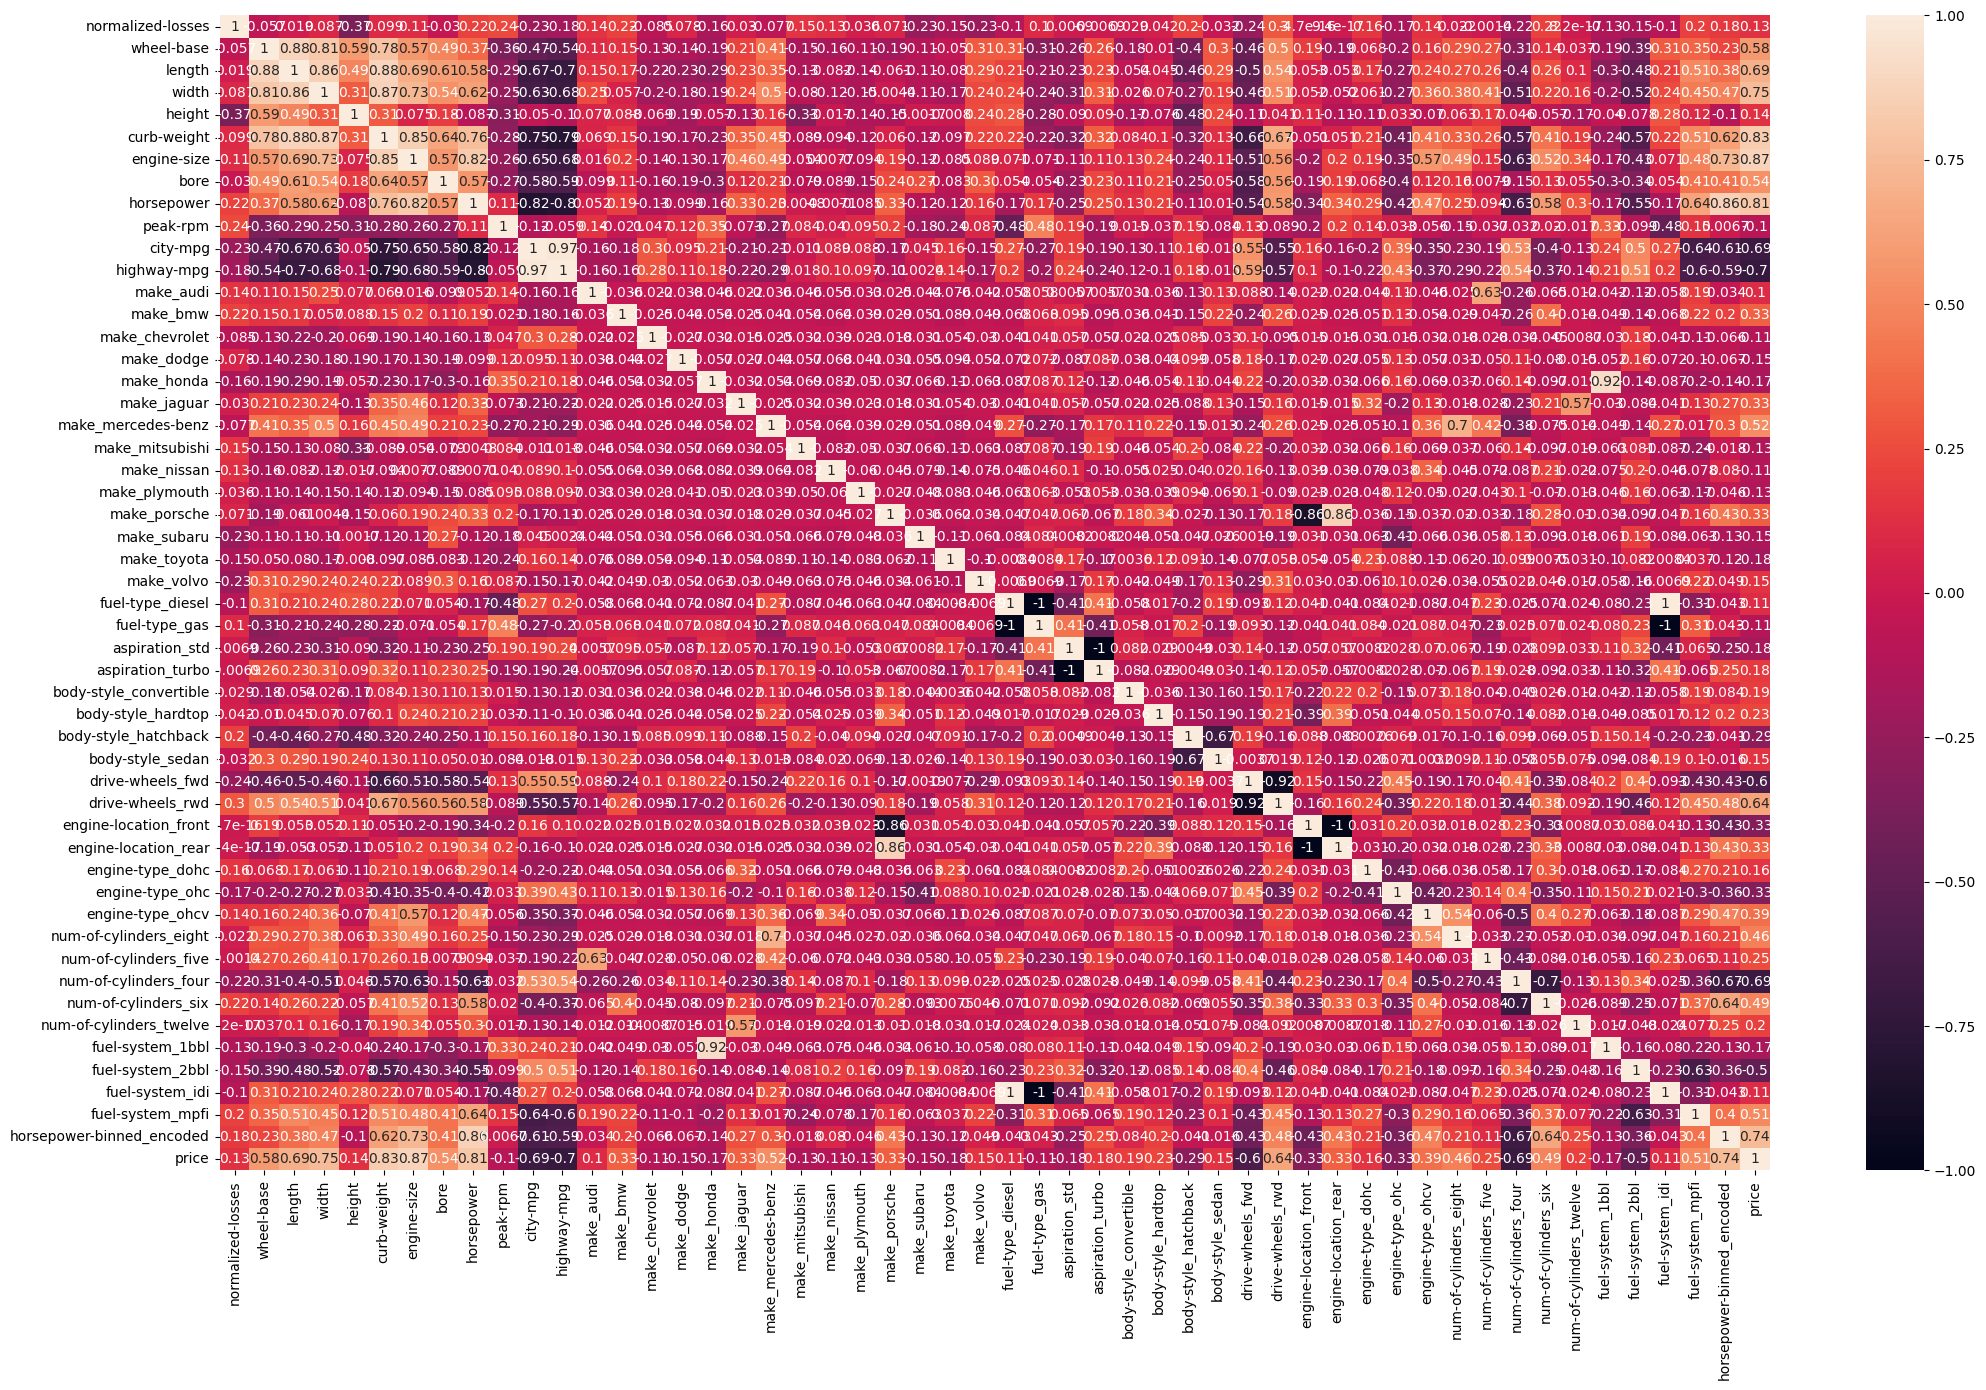

In [10]:
# check correlation again
corr_matrix = df_filtered.corr(method='pearson')
plt.figure(figsize=(25, 15))
sns.heatmap(corr_matrix, annot= True) # Display the correlation between the heatmap and variables in a visualize manner.

Calculate the correlation coefficient between continuous independent variables and select the
combination of independent variables whose correlation coefficient is greater than 0.8. It means linearly dependent, and one of the pair should be removed.

In [11]:
cols_pair = []
for index_ in corr_matrix.index:
  for col_ in corr_matrix.columns:
    if corr_matrix.loc[index_,col_] >= 0.8 and index_!=col_ and (col_,index_) not in cols_pair:
      cols_pair.append((index_,col_))
cols_pair

[('wheel-base', 'length'),
 ('wheel-base', 'width'),
 ('length', 'width'),
 ('length', 'curb-weight'),
 ('width', 'curb-weight'),
 ('curb-weight', 'engine-size'),
 ('curb-weight', 'price'),
 ('engine-size', 'horsepower'),
 ('engine-size', 'price'),
 ('horsepower', 'horsepower-binned_encoded'),
 ('horsepower', 'price'),
 ('city-mpg', 'highway-mpg'),
 ('make_honda', 'fuel-system_1bbl'),
 ('make_porsche', 'engine-location_rear'),
 ('fuel-type_diesel', 'fuel-system_idi')]

Length is highly correlated many times, can be removed. City-mpg, horsepower, can be removed. The ones who are highly correlated with price are neglected. make_honda, make_peugot, make_subaru are neglected since they are generated from encoding.  

In [12]:
# Drop one of each pair
df_filtered = df_filtered.drop(['length','curb-weight', 'city-mpg', 'horsepower'], axis = 1)

In [13]:
df_filtered.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 48 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   normalized-losses          201 non-null    float64
 1   wheel-base                 201 non-null    float64
 2   width                      201 non-null    float64
 3   height                     201 non-null    float64
 4   engine-size                201 non-null    int64  
 5   bore                       201 non-null    float64
 6   peak-rpm                   201 non-null    float64
 7   highway-mpg                201 non-null    int64  
 8   make_audi                  201 non-null    int64  
 9   make_bmw                   201 non-null    int64  
 10  make_chevrolet             201 non-null    int64  
 11  make_dodge                 201 non-null    int64  
 12  make_honda                 201 non-null    int64  
 13  make_jaguar                201 non-null    int64  

This is the final dataset after filter-based feature selection.